<a href="https://colab.research.google.com/github/Jayadeep19/pytorch/blob/master/Convolutions%20and%20CNN/Convolutional_layer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Convolutions and Convolutional layer

![gif](https://cdn.hashnode.com/res/hashnode/image/upload/v1666613592379/pUhJvPTCq.gif#center)

- Convolutions are the backbone of the Deep learning algorithms that understand images.
- It detects important features in the image such as edges, shapes etc.. By extracting those features it helps to learn the patterns in the images to perform various tasks.
- Convolutions are nothing but, sliding a small window over an Image and summing the results of the element wise multiplications between the overlapping values.
- For example, in the GIF above we are sliding three windows(kernels) over a 3 channel Image(color) and producing a single value for the overlapping pixels.
- The new map that results from this operation is called a feature map. It contains the low level information of many pixels combined.
- why is this important?
  - Imagine we train an MLP ([discussed before!](https://github.com/Jayadeep19/pytorch/tree/master/pytorch/MLP)), we have to train input number of neurons in the input layer and arbitary number of neurons in the hidden layer.
  - Each neuron is connected to all the neurons in the layer before. Thus increasin the number of computations needed.
  - Also, when we train the model to detect a number "1" we have to train all the neurons to recoginise the number  '1'. If this is not the case, if the number '1' appears in the top right corner of the image and the neurons representing those pixels did not recognise the number '1' then the it fails the task.
- So the main goal of Convolutions is to train the weights of the kernel that we slide over the image to recognise the number '1', so that no matter where the number '1' appears in the image, it recognises the number.
- This reduces the number of trainable parameters drastically and also preserve temporal dependencies of the pixels.

- For a convolutional layer there can be n number of convolution kernels that focus on different aspects of the image.
- These Neural Networks are widely used in Image Recognition, detection, Image analysis etc..
- Also check out [my master thesis](https://jayadeep19.github.io/til-notes/projects/master-thesis/) that involves various types of these tasks to generate a grasping rectangle on industrial tools for a robot to pick up!!
- check and play with the convolutions visually by visiting [visualiser](https://ezyang.github.io/convolution-visualizer/index.html)

In [19]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms as transform

import numpy
from matplotlib import pyplot as plt
from tqdm import tqdm

#To load the image from web
import io
import requests
from PIL import Image, ImageOps

## Convolutions with raw tensors
- We will use pytorch tensors and well know filters(kernels) first and then implement the convolutions using the pytorch 'functional module'

Loaded image is in RGB mode
size of loaded image is: (512, 720)


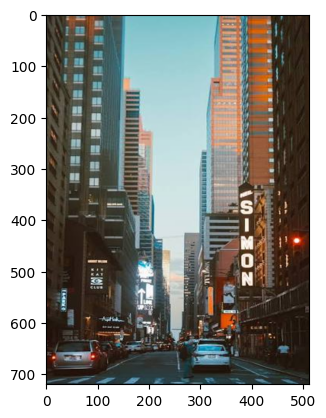

In [20]:
url = "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRb1dytAi26NwhHPu0lExh_41-VhoC0BhzaAv5-6wLyTw&s=10"

response = requests.get(url)
response.raise_for_status()

image_stream = io.BytesIO(response.content)
img = Image.open(image_stream)


if img.mode != 'RGB':
    img = img.convert('RGB')

print('Loaded image is in',img.mode, 'mode')

img = img.resize((512,720))
print(f'size of loaded image is: {img.size}')

plt.imshow(img)

In [21]:
# Transform the image to tensor of desired size(downsize)

t = transform.ToTensor()
#resize = transform.Resize(512)
#t_image = t(resize(img))
t_image = t(img)
print('reshaped image size is:', t_image.shape)

reshaped image size is: torch.Size([3, 720, 512])


- Edge detector for our image
- There are several kernel based [edge detectors](https://www.geeksforgeeks.org/digital-logic/image-edge-detection-operators-in-digital-image-processing/), I'll use prewitt operator.
- we have two matrices that finds the derivatives of the pixels along x and y directions. Once we have these gradient feature maps, we can add them to find the edges in our image.
 ![prewitt](https://image1.slideserve.com/2821049/sobel-and-prewitt-filters-cont-l.jpg)
- Our Image has many low contrast areas, it will be interesting to see how well the edge detector performs.


### pytoch kernels:

- pytorch expects the kernels to be of specific format.
- It needs to be in the 4D - **[out_channels, in_channels, kern_height, ker_width]**
  - out_channels: Number of kernels(filters) in the layer or convolutions, this determine the number of feature maps that are produced.
  - in_channels: This must match the channel number of Input image. Ex: if 3channels in image, we pass a 3 channel kernel
  - height and width of the kernel.

- And Input image of shape **[minibatch_sizee, in_channel, height, width]**
  - since we have ony one image we can just use squeeze(0)


In [22]:
# create the prewitt kernels as pytorch tensors
# x-direction gradient (apply vertical mask)
gx = torch.FloatTensor([[-1,0,1],[-1,0,1],[-1,0,1]]).unsqueeze(0)   #unsqueeze to match the pytorch format   #prewitt
#gx = torch.FloatTensor([[-1,0,1],[-2,0,2],[-1,0,1]]).unsqueeze(0)   #sobel
print(f'shape of the gx kernel is : {gx.shape}')

#but we only have 1 channel of our kernel, let us make three channels
gx = gx.repeat(3,1,1).unsqueeze(0)
print(f'shape of the gx kernel is : {gx.shape}')
print(gx)
# now we can see the shape of the kernel is in desired shape, 1 output feature, 3 input channels, 3*3 height*width



shape of the gx kernel is : torch.Size([1, 3, 3])
shape of the gx kernel is : torch.Size([1, 3, 3, 3])
tensor([[[[-1.,  0.,  1.],
          [-1.,  0.,  1.],
          [-1.,  0.,  1.]],

         [[-1.,  0.,  1.],
          [-1.,  0.,  1.],
          [-1.,  0.,  1.]],

         [[-1.,  0.,  1.],
          [-1.,  0.,  1.],
          [-1.,  0.,  1.]]]])


In [23]:
# repeat the same for y gradient (apply horizontal mask)
gy = torch.FloatTensor([[1,1,1],[0,0,0],[-1,-1,1]]).unsqueeze(0)   #prewitt
#gy = torch.FloatTensor([[1,2,1],[0,0,0],[-1,-2,1]]).unsqueeze(0)  #sobel
gy = gy.repeat(3,1,1).unsqueeze(0)
print(f'shape of the gy kernel is : {gy.shape}')
print(gy)

shape of the gy kernel is : torch.Size([1, 3, 3, 3])
tensor([[[[ 1.,  1.,  1.],
          [ 0.,  0.,  0.],
          [-1., -1.,  1.]],

         [[ 1.,  1.,  1.],
          [ 0.,  0.,  0.],
          [-1., -1.,  1.]],

         [[ 1.,  1.,  1.],
          [ 0.,  0.,  0.],
          [-1., -1.,  1.]]]])


> Note: we can also add the two feature maps and make a single kernel out of it, the the output channel would be 2 instead of 1: [1,3,3,3] -> [2,3,3,3]

### convolutions in pytorch
- We have defined the kernels and input image, now we have to perform convolutions. We can use a for loop to slide our kernels over the image and sum the elementwise multiplications.
- But this is a very inefficient way to perform convolutions, the researchers found a way to perform convolutions as a [matrix multiplications](https://lovellbrian.github.io/2023/10/23/Convolution.html), which is a very efficient way.
- Pytorch and other ml frameworks use this way to perform convolutions, so we will use `torch.nn.functional.conv2d` to perform our convolution

The shape of our feature map is : torch.Size([1, 1, 718, 510])


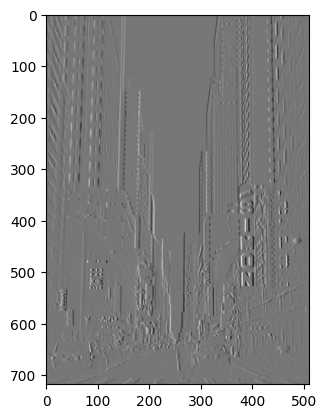

In [24]:
conv_1 = F.conv2d(t_image.unsqueeze(0), gx, bias = None, stride = 1, padding = 0)
print(f'The shape of our feature map is : {conv_1.shape}')

plt.imshow(conv_1.squeeze(0).squeeze(0), cmap = 'gray')

The shape of our feature map is : torch.Size([1, 1, 718, 510])


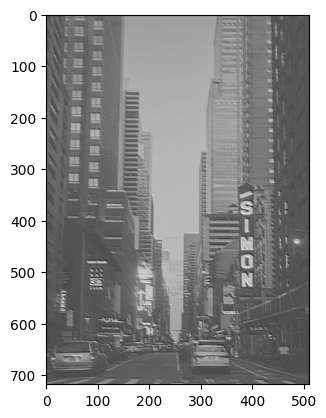

In [25]:
# since the image has buildings that will have a nice gradient differnce along this kernel

conv_2 = F.conv2d(t_image.unsqueeze(0), gy, bias = None, stride = 1, padding = 0)
print(f'The shape of our feature map is : {conv_2.shape}')

plt.imshow(conv_2.squeeze(0).squeeze(0), cmap = 'gray')

The shape of our feature map is : torch.Size([1, 1, 718, 510])


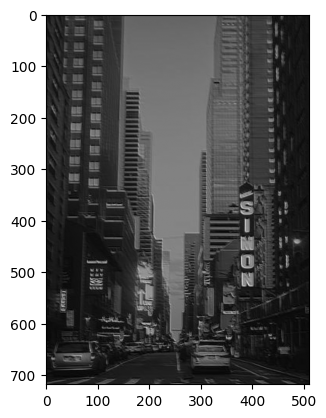

In [26]:
# we can now add the two gradients
# since the gradients can have positive and negative gradients, we take the square of the gradients and add them then take square root of hem to scale them down again
final_feature_map1 = (conv_1.pow(2) + conv_2.pow(2)).sqrt()
print(f'The shape of our feature map is : {final_feature_map1.shape}')
plt.imshow(final_feature_map1.squeeze(0).squeeze(0), cmap = "gray")

### Convolutional layers
- we can concatenate both the kernels to make them a single kernel.
- we do not have to do the individual convolutions seperate

The shape of the concatenated kernels is: torch.Size([2, 3, 3, 3])
The shape of the feature map with kernel of torch.Size([2, 3, 3, 3]) is : torch.Size([1, 718, 510])


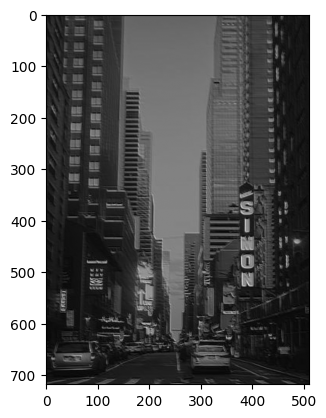

In [27]:
g_xy = torch.cat((gx,gy),0)
print(f'The shape of the concatenated kernels is: {g_xy.shape}')

conv_3 = F.conv2d(t_image.unsqueeze(0), g_xy, bias= None, stride = 1, padding = 0)

final_feature_map2 = conv_3.pow(2).sum(1).sqrt()

print(f"The shape of the feature map with kernel of {g_xy.shape} is : {final_feature_map2.shape}")
plt.imshow(final_feature_map2.squeeze(0), cmap = 'gray')

- We got the exact same edges in both cases!!

**BUT WAIT!!**
- In this we know that we want edges of the image so we used prewitt edge detector kernels, but what kernel weights would we use in a Convolutional Neural Network?
- we do not know what features the CNN is searching for to learn the patterns in the image, _**so our goal in training a CNN will be to learn these weights**_.
- Just like the MLP we trained, we can also use the same techniques to train the CNN to perform the desired task!!

## Train a Convolution Kernel
- we will try to train a single convolution kernel to learn the weights to detect edges.
- I thought of using [canny edge detector](https://docs.opencv.org/4.13.0/da/d22/tutorial_py_canny.html) from opencv to get the edges and use it for training, but it performs non-maxima supression, which we dinot perform.
- So we will use a simple guassian blur and subtract it from our image to get the edges

<class 'numpy.ndarray'>


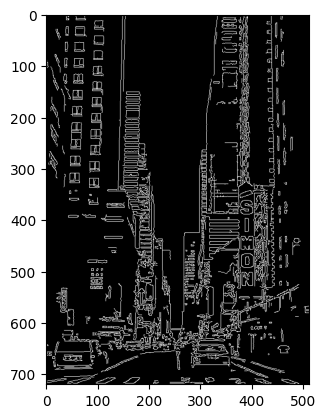

In [28]:
# First we will create a target image for our kernel to refer to while training.
# We can achieve this by applying 'canny edge detector' from opencv to get the edges of the image.

import cv2

#cv2.Canny requires the image to be numpy array.
np_img = numpy.asarray(ImageOps.grayscale(img))

target = cv2.Canny(np_img, 100,200)

plt.imshow(np_img, cmap = 'gray')
plt.imshow(target, cmap = 'gray')

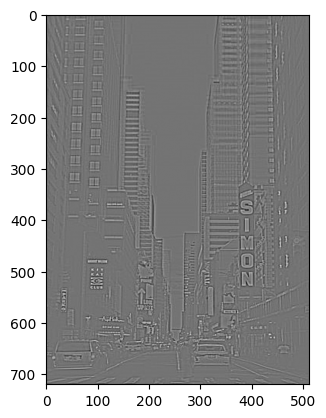

In [29]:
blur = transform.GaussianBlur(7, 4)
# Blur the image and subtract this from the original
# Blurring will leave only the high frequency components on the image
# By subtracting them from the original we should get only the high frequency components
target = t_image.unsqueeze(0) - blur(t_image.unsqueeze(0))
_ = plt.imshow(torch.squeeze(target[0, 0]), cmap='gray')

- create a convolution kernel and loop it to train for several epochs

In [30]:
# kernel- we will use nn.Conv2D because we want to train it so, we need the conv2D as a layer with trainable parameters
target_kernel = nn.Conv2d(out_channels=1, in_channels= 3, kernel_size=3, padding=1, stride = 1, bias= False)

#padding = 1 to match the output image dimensions to the target image dimensions

# also initiate our optimizer
optimizer = optim.SGD(target_kernel.parameters(), lr = 0.01)

In [31]:
target_kernel.weight.shape

torch.Size([1, 3, 3, 3])

In [32]:
# write the training loop.
loss_logger = []

for _ in tqdm(range(1000)):
  pred_image = target_kernel(t_image.unsqueeze(0))

  loss = (target- pred_image).pow(2).mean()
  loss_logger.append(loss.item())
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()


100%|██████████| 1000/1000 [00:22<00:00, 44.71it/s]


In [33]:
print(f'the learned weights of our kernel is: {target_kernel.weight}')
print(f'the kernel weights of our prewitt filter is: {g_xy}')

the learned weights of our kernel is: Parameter containing:
tensor([[[[-0.0879, -0.0165,  0.1644],
          [ 0.0717, -0.0185, -0.1476],
          [ 0.1137,  0.0316, -0.0504]],

         [[ 0.0802, -0.0740, -0.1164],
          [-0.0027, -0.0984,  0.1028],
          [ 0.0443, -0.1397,  0.0582]],

         [[-0.0372,  0.1745, -0.1290],
          [-0.1284,  0.2156, -0.1197],
          [-0.0332,  0.2022, -0.0381]]]], requires_grad=True)
the kernel weights of our prewitt filter is: tensor([[[[-1.,  0.,  1.],
          [-1.,  0.,  1.],
          [-1.,  0.,  1.]],

         [[-1.,  0.,  1.],
          [-1.,  0.,  1.],
          [-1.,  0.,  1.]],

         [[-1.,  0.,  1.],
          [-1.,  0.,  1.],
          [-1.,  0.,  1.]]],


        [[[ 1.,  1.,  1.],
          [ 0.,  0.,  0.],
          [-1., -1.,  1.]],

         [[ 1.,  1.,  1.],
          [ 0.,  0.,  0.],
          [-1., -1.,  1.]],

         [[ 1.,  1.,  1.],
          [ 0.,  0.,  0.],
          [-1., -1.,  1.]]]])


Text(0.5, 1.0, 'loss during training of our target kernel')

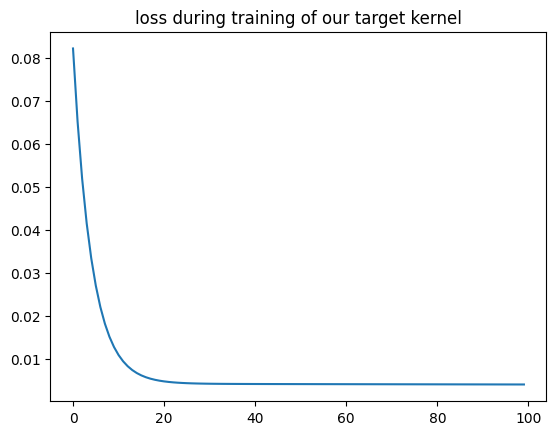

In [34]:
plt.plot(loss_logger[:100])
plt.title('loss during training of our target kernel')

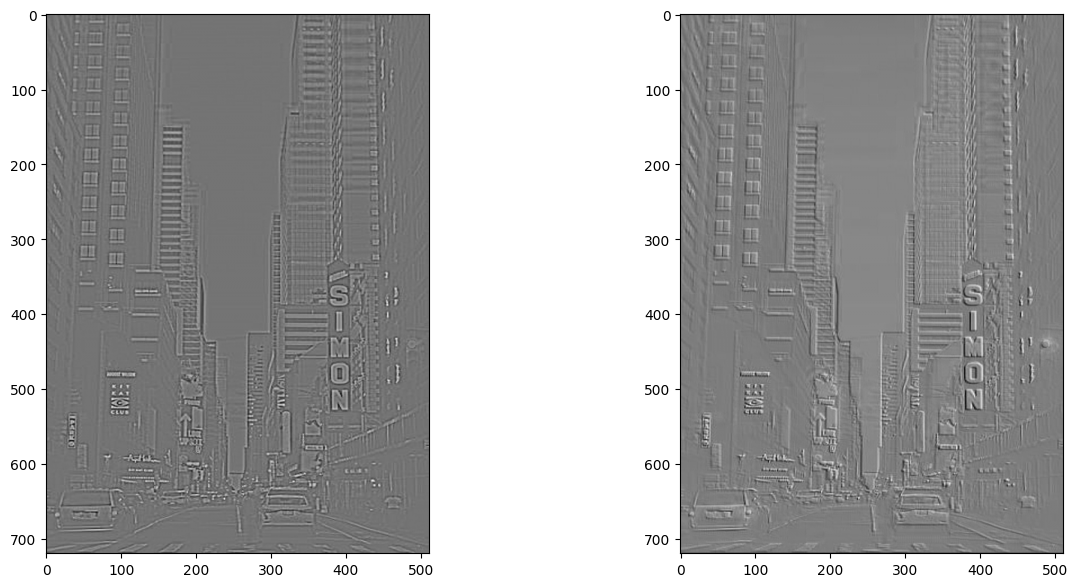

In [35]:
f, (ax1, ax2) = plt.subplots(1, 2, sharex=True, figsize = (15,7))
ax2.imshow(torch.squeeze(pred_image[0, 0].detach()), cmap='gray')
ax1.imshow(torch.squeeze(target[0, 0]), cmap='gray')

- we have sucessfully trained a 3*3 kernel to detect edges in our image!!